# Meme Kanseri Tanısında Makine Öğrenmesi: Tümör Örneklerinin İyi/Kötü Huylu Sınıflandırılması

**Proje türü:** Makine öğrenmesi · ikili sınıflandırma
**Veri seti:** Breast Cancer Wisconsin (Diagnostic) — UCI Machine Learning Repository, CC BY 4.0
https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

Bu not defteri yukarıdan aşağıya çalıştırılabilir (*Çalışma zamanı → Tümünü çalıştır*). Tüm şekiller `sekiller/` klasörüne, sayısal sonuçlar `sonuclar.json` dosyasına kaydedilir.

## 1. Problem tanımı

İnce iğne aspirasyonu (FNA) ile alınan meme kitlesi örneğinin mikroskop görüntüsünden ölçülen hücre çekirdeği özellikleri (yarıçap, doku, çevre, alan, düzgünlük, içbükeylik vb.) **girdi** olarak kullanılır. **Hedef çıktı**, kitlenin **kötü huylu (malign)** mı **iyi huylu (benign)** mı olduğudur. Gerçek dünyada bu tür bir model patoloğun yerine geçmez; ikinci bir göz olarak **şüpheli örnekleri öne çıkaran bir karar destek aracı** olabilir. Bu bağlamda kötü huylu bir kitleyi gözden kaçırmak (yanlış negatif), iyi huylu bir kitleyi yeniden incelemeye göndermekten (yanlış pozitif) çok daha maliyetlidir; bu yüzden **recall** (duyarlılık) temel metrik olarak ele alınmıştır.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, precision_recall_curve)

RS = 42
SEK = Path("sekiller"); SEK.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
KOTU, IYI = "#C2410C", "#0F766E"   # kötü huylu / iyi huylu renkleri
SONUC = {}

## 2. Veri setinin tanıtılması

In [2]:
ham = load_breast_cancer(as_frame=True)
X = ham.data.copy()
# scikit-learn'de 0 = malignant; pozitif sınıfı "kötü huylu" yapmak için etiketi çeviriyoruz
y = (ham.target == 0).astype(int).rename("kotu_huylu")

print("Örnek sayısı :", X.shape[0])
print("Özellik sayısı:", X.shape[1])
print("Sınıflar     :", y.map({1: "kötü huylu (1)", 0: "iyi huylu (0)"}).value_counts().to_dict())
print("Kötü huylu oranı: %{:.1f}".format(y.mean() * 100))
SONUC["veri"] = {"n": int(X.shape[0]), "p": int(X.shape[1]), "kotu": int(y.sum()), "iyi": int((1 - y).sum())}
X.iloc[:, :6].head()

Örnek sayısı : 569
Özellik sayısı: 30
Sınıflar     : {'iyi huylu (0)': 357, 'kötü huylu (1)': 212}
Kötü huylu oranı: %37.3


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
0,17.99,10.38,122.80,1001.0,0.11840,0.27760
1,20.57,17.77,132.90,1326.0,0.08474,0.07864
2,19.69,21.25,130.00,1203.0,0.10960,0.15990
3,11.42,20.38,77.58,386.1,0.14250,0.28390
4,20.29,14.34,135.10,1297.0,0.10030,0.13280


**Değişkenler.** Her görüntüdeki çekirdekler için 10 temel ölçüm hesaplanmıştır: *radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension*. Her ölçümün **ortalaması (mean)**, **standart hatası (error)** ve **en kötü üç değerinin ortalaması (worst)** alınarak 30 sayısal özellik elde edilmiştir. Kategorik değişken yoktur.

## 3. Veri keşfi

In [3]:
print("Eksik değer sayısı:", int(X.isnull().sum().sum()))
print("Tekrarlanan satır  :", int(X.duplicated().sum()))

# Aykırı değerler: IQR kuralı (Q1-1.5·IQR, Q3+1.5·IQR) dışında kalan gözlem sayısı
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
aykiri = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr))
aykiri_satir = int(aykiri.any(axis=1).sum())
print(f"En az bir özelliği aykırı olan örnek: {aykiri_satir} / {len(X)}")
print("Aykırı örneklerin kötü huylu oranı: %{:.0f}".format(y[aykiri.any(axis=1)].mean() * 100))
SONUC["kesif"] = {"eksik": int(X.isnull().sum().sum()), "aykiri_satir": aykiri_satir,
                  "aykiri_kotu_orani": float(y[aykiri.any(axis=1)].mean())}
aykiri.sum().sort_values(ascending=False).head(6)

Eksik değer sayısı: 0
Tekrarlanan satır  : 0
En az bir özelliği aykırı olan örnek: 171 / 569
Aykırı örneklerin kötü huylu oranı: %67


area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
dtype: int64

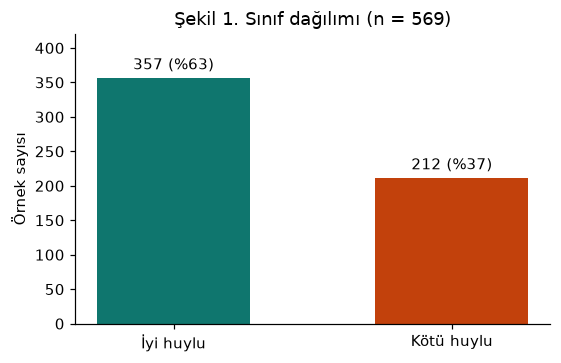

In [4]:
# Şekil 1 — sınıf dağılımı
sayim = y.map({1: "Kötü huylu", 0: "İyi huylu"}).value_counts()[["İyi huylu", "Kötü huylu"]]
fig, ax = plt.subplots(figsize=(5.2, 3.4))
c = ax.bar(sayim.index, sayim.values, color=[IYI, KOTU], width=0.55)
ax.bar_label(c, labels=[f"{v} (%{v / len(y) * 100:.0f})" for v in sayim.values], padding=3)
ax.set_title("Şekil 1. Sınıf dağılımı (n = 569)")
ax.set_ylabel("Örnek sayısı"); ax.set_ylim(0, 420)
plt.tight_layout(); plt.savefig(SEK / "1_sinif_dagilimi.png", dpi=200); plt.show()

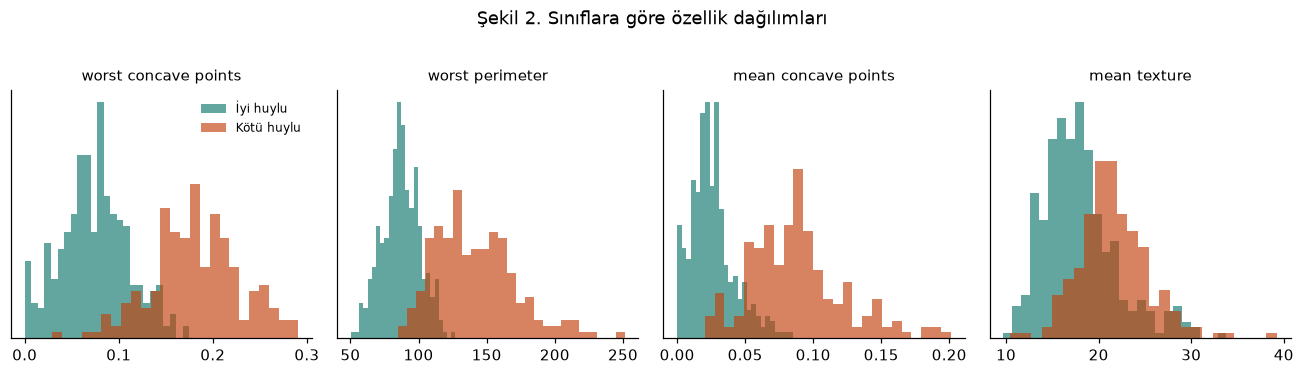

,Cohen d
worst concave points,1.639877
worst perimeter,1.617865
mean concave points,1.604846
worst radius,1.604515
mean perimeter,1.534631


In [5]:
# Şekil 2 — sınıflara göre en ayırt edici dört özelliğin dağılımı
secili = ["worst concave points", "worst perimeter", "mean concave points", "mean texture"]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
for ax, oz in zip(axes, secili):
    ax.hist(X.loc[y == 0, oz], bins=25, alpha=0.65, color=IYI, label="İyi huylu")
    ax.hist(X.loc[y == 1, oz], bins=25, alpha=0.65, color=KOTU, label="Kötü huylu")
    ax.set_title(oz, fontsize=10); ax.set_yticks([])
axes[0].legend(fontsize=8, frameon=False)
fig.suptitle("Şekil 2. Sınıflara göre özellik dağılımları", y=1.02)
plt.tight_layout(); plt.savefig(SEK / "2_ozellik_dagilimlari.png", dpi=200, bbox_inches="tight"); plt.show()

# Ayırt edicilik: iki sınıf ortalaması arasındaki farkın ortak standart sapmaya oranı (Cohen's d)
d = ((X[y == 1].mean() - X[y == 0].mean()) / X.std()).sort_values(ascending=False)
SONUC["kesif"]["cohen_d"] = {k: round(float(v), 2) for k, v in d.round(2).items()}
d.head(5).to_frame("Cohen d")

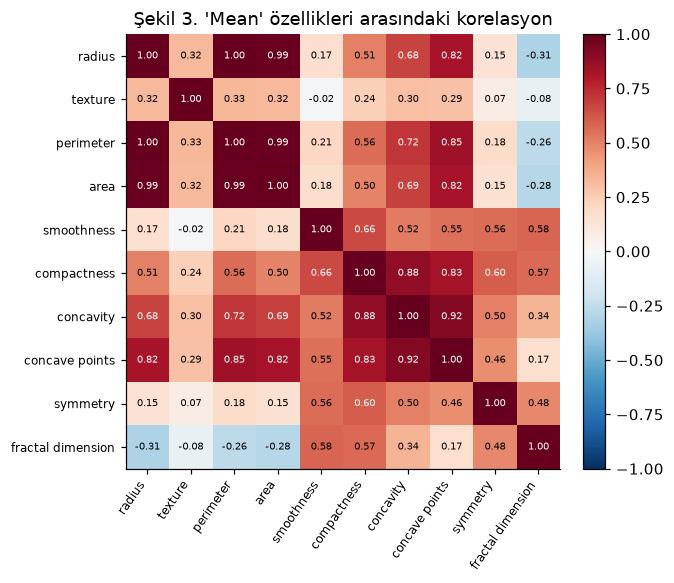

In [6]:
# Şekil 3 — 10 "mean" özelliği arasındaki korelasyon
ort = [c for c in X.columns if c.startswith("mean ")]
kor = X[ort].corr()
fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
etiket = [c.replace("mean ", "") for c in ort]
ax.set_xticks(range(10), etiket, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(10), etiket, fontsize=8)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{kor.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(kor.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, fraction=0.046, pad=0.04)
ax.set_title("Şekil 3. 'Mean' özellikleri arasındaki korelasyon")
plt.tight_layout(); plt.savefig(SEK / "3_korelasyon.png", dpi=200); plt.show()
SONUC["kesif"]["kor_radius_perimeter"] = round(float(kor.loc["mean radius", "mean perimeter"]), 3)
SONUC["kesif"]["kor_radius_area"] = round(float(kor.loc["mean radius", "mean area"]), 3)

**Keşif bulguları**

1. **Eksik veya tekrarlanan kayıt yok.** Veri temiz; eksik değer doldurma gerekmiyor.
2. **Sınıflar orta derecede dengesiz** (%63 iyi huylu, %37 kötü huylu, Şekil 1). Bu oran, sınıf ağırlıklandırma veya yeniden örnekleme gerektirecek kadar aşırı değil; ancak bölme işleminin **katmanlı (stratified)** yapılması ve yalnızca accuracy'ye güvenilmemesi gerekir.
3. **Boyut ve şekil özellikleri sınıfları güçlü biçimde ayırıyor.** Etki büyüklüğü (Cohen's d) en yüksek özellikler *worst concave points* (1.64), *worst perimeter* (1.62) ve *mean concave points* (1.60). Şekil 2'de bu özelliklerde iki sınıfın dağılımları büyük ölçüde ayrışırken *mean texture* gibi doku özelliklerinde belirgin bir örtüşme var.
4. **Güçlü çoklu doğrusallık var** (Şekil 3): *radius–perimeter* korelasyonu 1.00, *radius–area* 0.99. Bu üç özellik neredeyse aynı bilgiyi taşıyor; doğrusal modelde katsayıların yorumunu zorlaştırır ve düzenlileştirme (regularization) gerektirir.
5. **Aykırı değerler bilgi taşıyor.** IQR kuralına göre 569 örneğin 171'inde en az bir aykırı özellik var ve bu örneklerin **%67'si kötü huylu**. Aykırılık burada ölçüm hatası değil, büyük ve düzensiz tümörlerin doğal özelliği; bu yüzden aykırı değerler **silinmedi**.

## 4. Veri ön işleme

In [7]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RS)
print("Eğitim:", X_tr.shape, " kötü huylu oranı %{:.1f}".format(y_tr.mean() * 100))
print("Test  :", X_te.shape, " kötü huylu oranı %{:.1f}".format(y_te.mean() * 100))
SONUC["bolme"] = {"egitim": len(X_tr), "test": len(X_te), "test_kotu": int(y_te.sum())}

Eğitim: (455, 30)  kötü huylu oranı %37.4
Test  : (114, 30)  kötü huylu oranı %36.8


**Uygulanan ön işleme adımları ve gerekçeleri**

| Adım | Karar | Gerekçe |
|---|---|---|
| Eksik değer | Gerekmedi | Veride eksik değer yok |
| Aykırı değer | Silinmedi | Aykırı örneklerin %67'si kötü huylu; silmek tam da yakalanması gereken vakaları atmak olur |
| Encoding | Gerekmedi | Tüm özellikler sayısal; yalnızca hedef etiket "kötü huylu = 1" olacak şekilde çevrildi |
| Ölçekleme | StandardScaler (LR ve SVM için) | Özellik ölçekleri çok farklı (ör. *area* yüzlerce, *smoothness* 0.1 civarı); mesafe/katsayı tabanlı modeller ölçeğe duyarlı. Random Forest ölçekten etkilenmediği için uygulanmadı |
| Veri bölme | %80 eğitim (455) / %20 test (114), katmanlı | Test kümesinde kötü huylu oranı (%36.8) genel oranla aynı tutuldu |

Ölçekleyici bir **Pipeline** içinde tanımlandı; böylece çapraz doğrulamanın her katında yalnızca o katın eğitim verisiyle uyduruluyor ve doğrulama verisinden bilgi sızması önleniyor.

## 5–6. Model seçimi ve eğitimi

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
adaylar = {
    "Logistic Regression": (
        Pipeline([("olcek", StandardScaler()), ("model", LogisticRegression(max_iter=5000))]),
        {"model__C": [0.01, 0.1, 1, 10, 100]}),
    "Random Forest": (
        Pipeline([("model", RandomForestClassifier(random_state=RS))]),
        {"model__n_estimators": [200, 500], "model__max_depth": [None, 6], "model__min_samples_leaf": [1, 3]}),
    "SVM (RBF)": (
        # SVC olasılık vermez; olasılıkları çapraz doğrulamayla kalibre eden sarmalayıcı kullanılıyor
        Pipeline([("olcek", StandardScaler()),
                  ("model", CalibratedClassifierCV(SVC(kernel="rbf", random_state=RS), ensemble=False))]),
        {"model__estimator__C": [0.1, 1, 10, 100], "model__estimator__gamma": ["scale", 0.01, 0.001]}),
}

aramalar = {}
for ad, (pipe, izgara) in adaylar.items():
    gs = GridSearchCV(pipe, izgara, cv=cv, scoring="f1", refit=True)
    gs.fit(X_tr, y_tr)
    aramalar[ad] = gs
    print(f"{ad:20s} en iyi CV F1 = {gs.best_score_:.3f}   {gs.best_params_}")

SONUC["cv"] = {ad: {"f1": round(float(g.best_score_), 4), "params": {k.replace("model__", "").replace("estimator__", ""): v for k, v in g.best_params_.items()}}
               for ad, g in aramalar.items()}

Logistic Regression  en iyi CV F1 = 0.964   {'model__C': 1}


Random Forest        en iyi CV F1 = 0.952   {'model__max_depth': 6, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}


SVM (RBF)            en iyi CV F1 = 0.967   {'model__estimator__C': 1, 'model__estimator__gamma': 'scale'}


**Model seçimi ve gerekçe**

Üç farklı yaklaşım aynı katmanlı 5 katlı çapraz doğrulama ve ızgara araması (GridSearchCV, ölçüt: F1) ile karşılaştırıldı:

- **Logistic Regression** — yorumlanabilir temel model. L2 düzenlileştirme (C) çoklu doğrusallığın etkisini azaltır. En iyi: C = 1, CV F1 = 0.964.
- **Random Forest** — doğrusal olmayan ilişkileri ve etkileşimleri yakalar, ölçeklemeye ihtiyaç duymaz. En iyi: 200 ağaç, max_depth = 6, CV F1 = 0.952.
- **SVM (RBF çekirdek)** — 30 boyutlu, sınırları eğri olabilen bir uzayda geniş marjlı ayrım yapar; küçük-orta ölçekli veride güçlüdür. SVM olasılık üretmediği için `CalibratedClassifierCV` ile kalibre edildi. En iyi: C = 1, gamma = "scale", **CV F1 = 0.967**.

Final model **test verisine bakılmadan**, çapraz doğrulama F1 skoruna göre seçildi: **SVM (RBF)**. Üç modelin CV skorları arasındaki fark küçüktür (0.952–0.967); bu, problemin özellik uzayında iyi ayrışabildiğini gösterir.

## 7. Model değerlendirme

In [9]:
def metrikler(y_dogru, olasilik, esik=0.5):
    tahmin = (olasilik >= esik).astype(int)
    return {"Accuracy": accuracy_score(y_dogru, tahmin), "Precision": precision_score(y_dogru, tahmin),
            "Recall": recall_score(y_dogru, tahmin), "F1": f1_score(y_dogru, tahmin),
            "ROC-AUC": roc_auc_score(y_dogru, olasilik)}

olas_test = {ad: g.predict_proba(X_te)[:, 1] for ad, g in aramalar.items()}
tablo = pd.DataFrame({ad: metrikler(y_te, p) for ad, p in olas_test.items()}).T
SONUC["test_05"] = {ad: {k: round(float(v), 6) for k, v in r.items()} for ad, r in tablo.iterrows()}
tablo.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.965,0.975,0.929,0.951,0.996
Random Forest,0.965,1.000,0.905,0.950,0.995
SVM (RBF),0.974,0.976,0.952,0.964,0.995


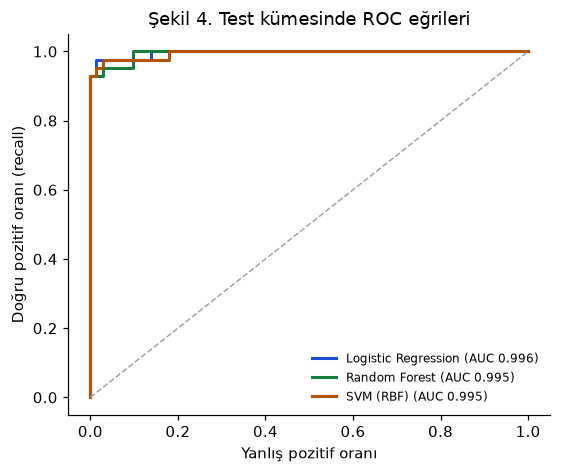

In [10]:
# Şekil 4 — ROC eğrileri
fig, ax = plt.subplots(figsize=(5.2, 4.4))
for (ad, p), renk in zip(olas_test.items(), ["#1D4ED8", "#15803D", "#B45309"]):
    fpr, tpr, _ = roc_curve(y_te, p)
    ax.plot(fpr, tpr, color=renk, lw=2, label=f"{ad} (AUC {roc_auc_score(y_te, p):.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="#9CA3AF", lw=1)
ax.set_xlabel("Yanlış pozitif oranı"); ax.set_ylabel("Doğru pozitif oranı (recall)")
ax.set_title("Şekil 4. Test kümesinde ROC eğrileri"); ax.legend(fontsize=8, frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig(SEK / "4_roc.png", dpi=200); plt.show()

### Karar eşiğinin recall'a göre ayarlanması

Varsayılan eşik 0.5'tir; ancak bu problemde kötü huylu vakayı kaçırmak daha maliyetli olduğundan eşik düşürülebilir. Eşik **test verisine bakılmadan**, yalnızca eğitim kümesindeki 5 katlı çapraz doğrulama olasılıkları (`cross_val_predict`) kullanılarak seçilmiştir: **recall ≥ 0.98** koşulunu sağlayan eşikler arasından precision'ı en yüksek olanı.

In [11]:
EN_IYI = max(aramalar, key=lambda a: aramalar[a].best_score_)   # CV F1'e göre seçim (test değil)
print("CV'ye göre seçilen model:", EN_IYI)

olas_cv = cross_val_predict(aramalar[EN_IYI].best_estimator_, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
prec, rec, esikler = precision_recall_curve(y_tr, olas_cv)
uygun = [(p, e) for p, r, e in zip(prec[:-1], rec[:-1], esikler) if r >= 0.98]
ESIK = float(max(uygun)[1])
print(f"Seçilen eşik: {ESIK:.3f}")

karsilastir = pd.DataFrame({"Eşik 0.50": metrikler(y_te, olas_test[EN_IYI], 0.5),
                            f"Eşik {ESIK:.2f}": metrikler(y_te, olas_test[EN_IYI], ESIK)}).T
SONUC["secilen"] = {"model": EN_IYI, "esik": round(ESIK, 3),
                    "esik05": {k: round(float(v), 6) for k, v in karsilastir.iloc[0].items()},
                    "esikAyarli": {k: round(float(v), 6) for k, v in karsilastir.iloc[1].items()}}
karsilastir.round(3)

CV'ye göre seçilen model: SVM (RBF)
Seçilen eşik: 0.247


,Accuracy,Precision,Recall,F1,ROC-AUC
Eşik 0.50,0.974,0.976,0.952,0.964,0.995
Eşik 0.25,0.965,0.932,0.976,0.953,0.995


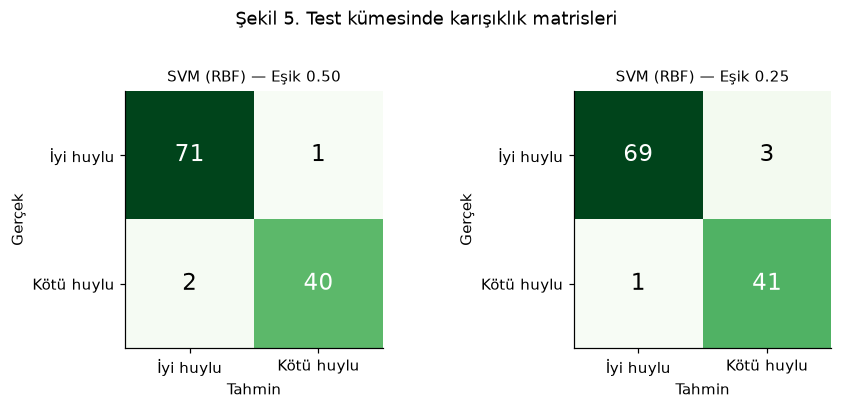

In [12]:
# Şekil 5 — seçilen modelin karışıklık matrisleri (eşik 0.50 ve ayarlı eşik)
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.6))
cms = {}
for ax, (baslik, esik) in zip(axes, [("Eşik 0.50", 0.5), (f"Eşik {ESIK:.2f}", ESIK)]):
    cm = confusion_matrix(y_te, (olas_test[EN_IYI] >= esik).astype(int), labels=[0, 1])
    cms[baslik] = cm.tolist()
    ax.imshow(cm, cmap="Greens")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=15,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["İyi huylu", "Kötü huylu"]); ax.set_yticks([0, 1], ["İyi huylu", "Kötü huylu"])
    ax.set_xlabel("Tahmin"); ax.set_ylabel("Gerçek"); ax.set_title(f"{EN_IYI} — {baslik}", fontsize=10)
fig.suptitle("Şekil 5. Test kümesinde karışıklık matrisleri", y=1.02)
plt.tight_layout(); plt.savefig(SEK / "5_karisiklik.png", dpi=200, bbox_inches="tight"); plt.show()
SONUC["secilen"]["cm"] = cms

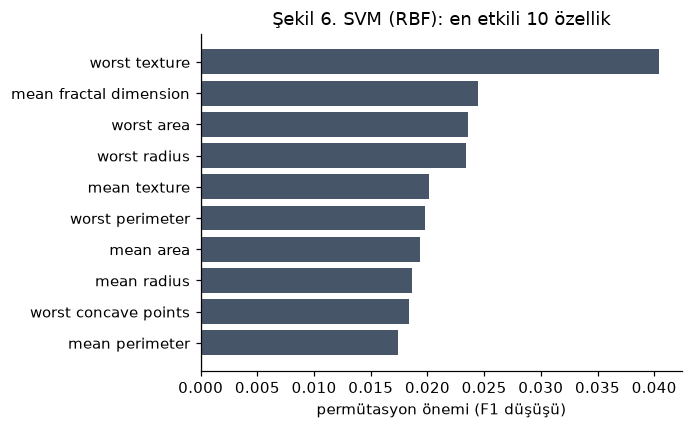

In [13]:
# Şekil 6 — modelin en çok dayandığı özellikler
model = aramalar[EN_IYI].best_estimator_.named_steps["model"]
if hasattr(model, "coef_"):
    onem = pd.Series(model.coef_[0], index=X.columns); baslik = "standartlaştırılmış katsayı"
elif hasattr(model, "feature_importances_"):
    onem = pd.Series(model.feature_importances_, index=X.columns); baslik = "önem (Gini)"
else:
    from sklearn.inspection import permutation_importance
    pi = permutation_importance(aramalar[EN_IYI].best_estimator_, X_te, y_te, scoring="f1", n_repeats=30, random_state=RS)
    onem = pd.Series(pi.importances_mean, index=X.columns); baslik = "permütasyon önemi (F1 düşüşü)"
ilk = onem.reindex(onem.abs().sort_values(ascending=False).index).head(10)[::-1]
fig, ax = plt.subplots(figsize=(6.4, 4))
# Katsayılarda yön anlamlı (kötü huylu/iyi huylu); permütasyon/Gini öneminde yön yok, nötr renk kullanılır
renkler = [KOTU if v > 0 else IYI for v in ilk.values] if hasattr(model, "coef_") else "#475569"
ax.barh(ilk.index, ilk.values, color=renkler)
ax.axvline(0, color="#6B7280", lw=0.8)
ax.set_title(f"Şekil 6. {EN_IYI}: en etkili 10 özellik"); ax.set_xlabel(baslik)
plt.tight_layout(); plt.savefig(SEK / "6_ozellik_onemi.png", dpi=200); plt.show()
SONUC["onem"] = {"tur": baslik, "ilk5": {k: round(float(v), 3) for k, v in ilk[::-1].head(5).items()}}

**Değerlendirme yorumu**

- **Varsayılan eşikte (0.50)** SVM test kümesinde accuracy 0.974, precision 0.976, **recall 0.952**, F1 0.964 elde etti: 42 kötü huylu vakanın 40'ını yakaladı, 2'sini kaçırdı; 72 iyi huyludan yalnızca 1'ine yanlış alarm verdi.
- **Recall'a göre ayarlanan eşikte (0.25)** recall **0.976**'ya çıktı (42'de 41), buna karşılık yanlış alarm sayısı 1'den 3'e yükseldi (precision 0.932). Tıbbi tarama bağlamında 2 ek "tekrar incele" kararı, 1 kaçırılan kanser vakasından daha kabul edilebilir bir bedeldir.
- **ROC-AUC değerleri üç modelde de 0.99 üzerinde** (Şekil 4); yani sıralama başarısı neredeyse aynı. Modeller arasındaki asıl fark, hangi eşikte nasıl bir precision–recall dengesi kurdukları.
- Test kümesinde yalnızca 42 kötü huylu örnek bulunduğundan **tek bir örnek recall'u ~2.4 puan değiştirir**. Modeller arasındaki 1–2 örneklik farklar istatistiksel olarak güçlü bir üstünlük anlamına gelmez.
- **Özellik önemi** (Şekil 6, permütasyon önemi): model en çok *worst texture*, *mean fractal dimension* ve boyut özelliklerine (*worst area*, *worst radius*) dayanıyor. Boyut özellikleri birbiriyle çok yüksek korelasyonlu olduğu için önem aralarında paylaşılıyor; tek tek değerleri düşük görünse de grup olarak en belirleyici bilgi kaynağı bunlar.

## 8. Hata analizi

In [14]:
tahmin = (olas_test[EN_IYI] >= ESIK).astype(int)
hata = X_te.assign(gercek=y_te, olasilik=olas_test[EN_IYI].round(3), tahmin=tahmin)[tahmin != y_te]
hata["tur"] = np.where(hata["gercek"] == 1, "Yanlış negatif (kaçırılan kötü huylu)", "Yanlış pozitif (gereksiz alarm)")
goster = ["tur", "olasilik", "worst concave points", "worst perimeter", "mean texture", "worst area"]
SONUC["hatalar"] = hata[goster].assign(**{c: hata[c].round(3) for c in goster[2:]}).to_dict(orient="records")

# Hatalı örnekleri sınıf medyanlarıyla karşılaştır
medyan = X_tr.groupby(y_tr)[goster[2:]].median().rename(index={0: "İyi huylu medyanı", 1: "Kötü huylu medyanı"})
SONUC["medyan"] = {i: {k: round(float(v), 3) for k, v in r.items()} for i, r in medyan.iterrows()}
display(hata[goster]); display(medyan.round(3))

,tur,olasilik,worst concave points,worst perimeter,mean texture,worst area
73,Yanlış negatif (kaçırılan kötü huylu),0.053,0.13830,110.30,15.79,812.4
208,Yanlış pozitif (gereksiz alarm),0.574,0.11260,99.48,22.54,639.3
314,Yanlış pozitif (gereksiz alarm),0.499,0.00000,56.65,18.60,240.1
71,Yanlış pozitif (gereksiz alarm),0.264,0.04786,62.56,14.64,284.4


,worst concave points,worst perimeter,mean texture,worst area
kotu_huylu,,,,
İyi huylu medyanı,0.074,87.00,17.53,547.8
Kötü huylu medyanı,0.183,139.35,21.52,1317.5


In [15]:
Path("sonuclar.json").write_text(json.dumps(SONUC, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
print("sonuclar.json kaydedildi")

sonuclar.json kaydedildi


**Hata analizi (ayarlı eşik, 4 hata)**

- **Kaçırılan kötü huylu vaka (örnek #73, olasılık 0.05):** Model bu örnekten neredeyse emin biçimde yanılıyor. 30 özelliğin yalnızca **10'unda** kötü huylu sınıfın medyanına daha yakın; *worst perimeter* (110) ve *worst area* (812) iki sınıfın medyanı arasında, *mean texture* (15.8) ise iyi huylu medyanının bile altında. Yani bu, ölçümlerin çoğunda iyi huylu bir kitle gibi görünen **atipik bir malign vaka**. Eşiği daha da düşürmek onu yakalamaz (olasılığı 0.05), yalnızca yanlış alarmları artırır; bu tür vakalar bu 30 özellikle ayırt edilemiyor.
- **Yanlış alarmlar (örnek #208, #314, #71):** Üçü de iyi huylu ama sıra dışı ölçümlere sahip. #314 ve #71 küçük hücreli olmalarına rağmen **standart hata (error) özelliklerinde aşırı değerler** taşıyor (*symmetry error*, *fractal dimension error* için z ≈ 6): çekirdekler arasında ölçüm değişkenliği çok yüksek. #208'de ise *worst symmetry* ve *compactness* belirgin biçimde yüksek, yani şekil düzensizliği kötü huylu kitleleri andırıyor.
- **Ortak örüntü:** Model, boyut ve şekil özelliklerinin aynı yönde sinyal verdiği "tipik" vakalarda çok başarılı; hatalar, özelliklerin birbiriyle **çeliştiği** sınırda vakalarda toplanıyor.

## 9. Sonuç ve geliştirme önerileri

- Hücre çekirdeği ölçümlerinden kitlenin kötü huylu olup olmadığını **%97.4 doğruluk ve 0.995 ROC-AUC** ile tahmin eden bir SVM modeli geliştirildi. Recall'u önceleyen eşikle kötü huylu vakaların **%97.6'sı** yakalandı.
- **Güçlü yönler:** sızıntısız (pipeline + yalnızca eğitim verisinde seçilen eşik) değerlendirme, üç modelle karşılaştırma, tıbbi maliyete uygun eşik seçimi.
- **Zayıf yönler:** veri küçük (569 örnek) ve tek bir merkezden; test kümesindeki 42 kötü huylu vaka metrikleri oynak kılar. Atipik vakaları ayırt edecek bilgi bu özelliklerde yok. Model bir **karar destek aracıdır**, tanı koymaz.
- **Geliştirme önerileri:** (1) tekrarlı çapraz doğrulama ile metriklerin güven aralığını raporlamak; (2) farklı merkezlerden veriyle dış doğrulama; (3) yüksek korelasyonlu boyut özelliklerini azaltıp (ör. yalnızca *radius* tutmak veya PCA) daha yorumlanabilir bir model kurmak; (4) olasılığı 0.2–0.6 arasında kalan "belirsiz" örnekleri otomatik olarak uzman incelemesine yönlendiren üç bölgeli bir karar kuralı.